# Do commodity price moves lead industry returns?

Course project for APM_5FI15_AE "ML for Trading" (ENSAE Paris, M2 SFA), Selim-Antoine Lali and Quentin Borne, October 2026.

*Work in progress: for now the notebook only loads the data (Section 2).*

**Hypothesis.** Last month's moves in commodity prices (oil, gas, coal, metals, grains) predict next month's returns of the Ken French industry portfolios. The sign should depend on whether an industry produces the commodity (Oil, Coal, Mines, Gold, Agric) or uses it as an input (Trans, Chems, Autos, Util, Steel). The mechanism we have in mind is a slow diffusion of information from commodity markets to stock prices (Hong, Torous and Valkanov, 2007; Driesprong, Jacobsen and Maat, 2008).

**Plan of the notebook**:

1. Introduction
2. Data
3. Analytics and learning strategies
4. Empirical results: baseline and robustness
5. Conclusion

## Setup

The notebook only uses standard scientific Python packages (listed in `environment.yml`). Each dataset is downloaded once and cached as a parquet file in the `data/` folder next to the notebook. This folder is committed with the notebook, so the results can be reproduced even if a source is revised or a link breaks.

In [556]:
import io
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

DATA_DIR = Path("data")  # downloads are cached here as parquet files
DATA_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (9, 4.5)

## 1. Introduction

*To be written.*

## 2. Data

### 2.1 Industry returns: Ken French's 49 industry portfolios

Monthly value-weighted returns, in percent, of the 49 Fama-French industry portfolios, downloaded from Ken French's data library. We use the 49-industry classification rather than a coarser one (12 or 30 industries) because commodity exposures are specific to narrow industries: Oil, Coal, Gold, Mines and Agric exist as separate portfolios only at this level of detail; in the 12-industry classification they are merged into Energy, Other and Non-durables.

The csv file stacks several tables (monthly and annual returns, value- and equal-weighted, number of firms...). We only keep the first one, the monthly value-weighted returns. Missing values are coded `-99.99`: nine industries start after July 1926, some of them only in the 1960s.

In [557]:
KF_URL = "http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_CSV.zip"


def load_industry_returns():
    """Monthly value-weighted returns (in %) of the 49 Fama-French industries, from Ken French's data library."""
    cache = DATA_DIR / "kf49_monthly_returns.parquet"
    if cache.exists():
        return pd.read_parquet(cache)

    response = requests.get(KF_URL, timeout=60)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        text = archive.read(archive.namelist()[0]).decode()

    # The tables are separated by blank lines; we keep the first one
    lines = text.splitlines()
    for i, line in enumerate(lines):
        if "Average Value Weighted Returns -- Monthly" in line:
            start = i + 1
            break
    end = start
    while lines[end].strip() != "":
        end += 1

    returns = pd.read_csv(io.StringIO("\n".join(lines[start:end])), index_col=0)
    returns.index = pd.to_datetime(returns.index.astype(str), format="%Y%m")
    returns.index.name = "month"
    returns.columns = returns.columns.str.strip()
    returns = returns.replace(-99.99, np.nan)  # Ken French's code for missing values
    returns.to_parquet(cache)
    return returns


industry_returns = load_industry_returns()
print(f"{industry_returns.shape[1]} industries, {len(industry_returns)} months, "
      f"from {industry_returns.index[0]:%Y-%m} to {industry_returns.index[-1]:%Y-%m}")
display(industry_returns.tail(3).round(2))
print("The 49 industries:", ", ".join(industry_returns.columns))

49 industries, 1203 months, from 1926-07 to 2026-09


,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,Clths,Hlth,MedEq,Drugs,Chems,Rubbr,...,Hardw,Softw,Chips,LabEq,Paper,Boxes,Trans,Whlsl,Rtail,Meals,Banks,Insur,RlEst,Fin,Other
month,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-07-01,-6.16,4.69,5.89,1.30,2.28,1.62,0.05,6.47,-0.44,1.53,3.97,5.68,-0.58,-1.15,-6.31,...,-1.63,6.22,-5.16,-13.00,1.93,2.34,0.14,1.88,6.79,1.26,4.25,3.86,2.82,6.72,2.61
2026-08-01,5.71,2.45,0.15,0.33,-1.24,-2.58,6.47,-0.58,1.41,-8.73,-0.34,4.61,6.21,2.30,-1.52,...,0.41,6.13,4.49,2.48,-2.09,-2.26,1.45,0.36,-3.77,-0.05,0.13,-1.06,-1.47,4.97,-1.85
2026-09-01,-8.36,-9.80,-3.84,-8.03,1.21,-5.75,-12.01,-4.89,-2.56,-7.20,0.51,-6.64,-0.58,-7.66,1.78,...,5.31,2.21,6.01,8.22,-7.99,-8.08,-9.26,-4.06,-4.22,-8.78,-6.99,-6.17,-13.05,-9.66,-2.02


The 49 industries: Agric, Food, Soda, Beer, Smoke, Toys, Fun, Books, Hshld, Clths, Hlth, MedEq, Drugs, Chems, Rubbr, Txtls, BldMt, Cnstr, Steel, FabPr, Mach, ElcEq, Autos, Aero, Ships, Guns, Gold, Mines, Coal, Oil, Util, Telcm, PerSv, BusSv, Hardw, Softw, Chips, LabEq, Paper, Boxes, Trans, Whlsl, Rtail, Meals, Banks, Insur, RlEst, Fin, Other


In [558]:
# The industries that start after July 1926
has_gaps = industry_returns.columns[industry_returns.isna().any()]
pd.DataFrame({
    "first month": industry_returns[has_gaps].notna().idxmax().dt.strftime("%Y-%m"),
    "missing months": industry_returns[has_gaps].isna().sum(),
})

,first month,missing months
Soda,1963-07,444
Hlth,1969-07,516
Rubbr,1930-07,60
FabPr,1963-07,444
Guns,1963-07,444
Gold,1963-07,444
PerSv,1927-07,12
Softw,1965-07,468
Paper,1929-07,36


### 2.2 Commodity prices: the World Bank Pink Sheet

All commodity data come from a single source, the World Bank's Commodity Price Data, known as the "Pink Sheet": monthly average prices, in nominal US dollars, of about 70 commodities since January 1960. We chose it because it is the longest freely available monthly dataset that covers energy, metals and agricultural commodities together, in one documented file. We keep 24 commodities in six groups: energy, industrial metals, precious metals, grains, softs and livestock.

Two remarks on timing, since the whole project is about using *lagged* commodity moves:

- A value dated month $t$ is the average of the prices observed during month $t$. It is known at the end of month $t$, so it can be used to take positions for month $t+1$ without look-ahead bias.
- Monthly averages are smoother than end-of-month prices, which creates some autocorrelation in monthly changes (Working, 1960). We will check later that the results do not depend on this choice, for example with end-of-month futures prices.

In [559]:
PINK_SHEET_URL = ("https://thedocs.worldbank.org/en/doc/74e8be41ceb20fa0da750cda2f6b9e4e-0050012026"
                  "/related/CMO-Historical-Data-Monthly.xlsx")


def load_commodity_prices():
    """Monthly average commodity prices in nominal US dollars, from the World Bank Pink Sheet (since 1960)."""
    cache = DATA_DIR / "pink_sheet_monthly_prices.parquet"
    if cache.exists():
        return pd.read_parquet(cache)

    response = requests.get(PINK_SHEET_URL, timeout=60)
    response.raise_for_status()
    # In the "Monthly Prices" sheet, row 5 has the commodity names, row 6 the units, and the data start at row 7
    prices = pd.read_excel(io.BytesIO(response.content), sheet_name="Monthly Prices",
                           header=4, skiprows=[5], index_col=0)
    prices.index = pd.to_datetime(prices.index, format="%YM%m")  # dates are written like "1960M01"
    prices.index.name = "month"
    prices.columns = prices.columns.str.replace("**", "", regex=False).str.strip()  # "**" marks a footnote
    prices = prices.apply(pd.to_numeric, errors="coerce")
    prices.to_parquet(cache)
    return prices


pink_sheet = load_commodity_prices()
print(f"{pink_sheet.shape[1]} series, {len(pink_sheet)} months, "
      f"from {pink_sheet.index[0]:%Y-%m} to {pink_sheet.index[-1]:%Y-%m}")

71 series, 802 months, from 1960-01 to 2026-10


In [560]:
print(f"{pink_sheet.shape[1]} commodities, {len(pink_sheet)} months, "
      f"from {pink_sheet.index[0]:%Y-%m} to {pink_sheet.index[-1]:%Y-%m}")

display(pink_sheet.tail(3))
print(f"The {pink_sheet.shape[1]} commodities:", ", ".join(pink_sheet.columns))

71 commodities, 802 months, from 1960-01 to 2026-10


,"Crude oil, average","Crude oil, Brent","Crude oil, Dubai","Crude oil, WTI","Coal, Australian","Coal, South African","Natural gas, US","Natural gas, Europe","Liquefied natural gas, Japan",Natural gas index,Cocoa,"Coffee, Arabica","Coffee, Robusta","Tea, avg 3 auctions","Tea, Colombo",...,Phosphate rock,DAP,TSP,Urea,Potassium chloride,Aluminum,"Iron ore, cfr spot",Copper,Lead,Tin,Nickel,Zinc,Gold,Platinum,Silver
month,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-08-01,84.4,90.9,79.7,82.7,135.2,96.8,2.77,21.11,15.27,144.3,5.95,7.97,3.98,2.91,3.61,...,170.0,793.5,704.4,390.0,386.9,3251,96.3,14326,1855,55385,16751,3875,4411,1780,65.4
2026-09-01,102.3,116.8,93.3,96.9,147.1,98.2,2.95,25.42,16.26,167.7,5.92,7.26,3.69,2.86,3.73,...,170.0,800.6,690.0,407.5,367.5,3283,97.7,14474,1873,53712,16324,4021,4319,1784,64.6
2026-10-01,108.5,125.0,102.7,97.7,152.3,100.0,2.96,28.50,16.59,182.7,5.75,7.40,3.63,2.88,3.75,...,170.0,803.1,692.0,420.0,357.5,3061,90.8,14508,1860,51696,15436,3818,4105,1621,57.0


The 71 commodities: Crude oil, average, Crude oil, Brent, Crude oil, Dubai, Crude oil, WTI, Coal, Australian, Coal, South African, Natural gas, US, Natural gas, Europe, Liquefied natural gas, Japan, Natural gas index, Cocoa, Coffee, Arabica, Coffee, Robusta, Tea, avg 3 auctions, Tea, Colombo, Tea, Kolkata, Tea, Mombasa, Coconut oil, Groundnuts, Fish meal, Groundnut oil, Palm oil, Palm kernel oil, Soybeans, Soybean oil, Soybean meal, Rapeseed oil, Sunflower oil, Barley, Maize, Sorghum, Rice, Thai 5%, Rice, Thai 25%, Rice, Thai A.1, Rice, Viet Namese 5%, Wheat, US SRW, Wheat, US HRW, Banana, Europe, Banana, US, Orange, Beef, Chicken, Lamb, Shrimps, Mexican, Sugar, EU, Sugar, US, Sugar, world, Tobacco, US import u.v., Logs, Cameroon, Logs, Malaysian, Sawnwood, Cameroon, Sawnwood, Malaysian, Plywood, Cotton, A Index, Rubber, TSR20, Rubber, RSS3, Phosphate rock, DAP, TSP, Urea, Potassium chloride, Aluminum, Iron ore, cfr spot, Copper, Lead, Tin, Nickel, Zinc, Gold, Platinum, Silver


In [561]:
# The 24 commodities used in our project, by group (names as in the Pink Sheet)
COMMODITY_GROUPS = {
    "energy": ["Crude oil, average", "Crude oil, Brent", "Natural gas, US", "Coal, Australian"],
    "industrial metals": ["Copper", "Aluminum", "Nickel", "Zinc", "Lead", "Tin", "Iron ore, cfr spot"],
    "precious metals": ["Gold", "Silver", "Platinum"],
    "grains": ["Wheat, US HRW", "Maize", "Soybeans", "Rice, Thai 5%"],
    "softs": ["Sugar, world", "Cotton, A Index", "Coffee, Arabica", "Cocoa"],
    "livestock": ["Beef", "Chicken"],
}

commodity_group = {}
for group, names in COMMODITY_GROUPS.items():
    for name in names:
        commodity_group[name] = group
commodity_group = pd.Series(commodity_group, name="group")

commodity_prices = pink_sheet[commodity_group.index]

pd.DataFrame({
    "group": commodity_group,
    "first month": commodity_prices.notna().idxmax().dt.strftime("%Y-%m"),
    "months": commodity_prices.notna().sum(),
    "last price": commodity_prices.iloc[-1].round(2),
})

,group,first month,months,last price
"Crude oil, average",energy,1960-01,802,108.50
"Crude oil, Brent",energy,1960-01,802,125.00
"Natural gas, US",energy,1960-01,802,2.96
"Coal, Australian",energy,1970-01,682,152.30
Copper,industrial metals,1960-01,802,14508.00
Aluminum,industrial metals,1960-01,802,3061.00
Nickel,industrial metals,1960-01,802,15436.00
Zinc,industrial metals,1960-01,802,3818.00
Lead,industrial metals,1960-01,802,1860.00
Tin,industrial metals,1960-01,802,51696.00


### 2.3 A first look

Several series are flat in the 1960s: the price of oil was administered until 1973 and the gold price was fixed at 35 dollars an ounce until 1968. For these commodities the informative sample really starts in the early 1970s, which we will keep in mind when choosing the estimation period.

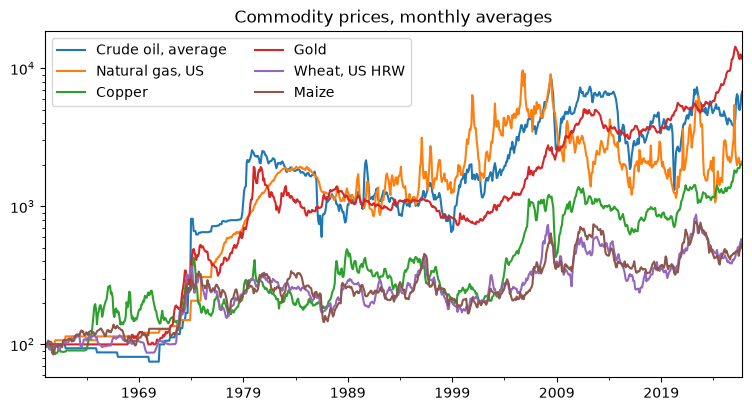

In [562]:
shown = ["Crude oil, average", "Natural gas, US", "Copper", "Gold", "Wheat, US HRW", "Maize"]
rebased = 100 * commodity_prices[shown] / commodity_prices[shown].iloc[0]

ax = rebased.plot(logy=True, title="Commodity prices, monthly averages")
ax.set_xlabel("")
ax.legend(loc="upper left", ncol=2)
plt.show()

### 2.4 Commodity changes and the common sample

Prices are not usable as features, so we work with monthly log price changes, in percent to match the unit of the industry returns. The two panels are then aligned on a common monthly index: the industry returns run from July 1926 to September 2026 and the commodity prices from January 1960 to October 2026, so the common sample is February 1960 to September 2026 (the first month is lost to the difference and October 2026 has no industry return yet).

One choice has to be made about the evaluation period. Oil prices were administered until 1973 and the gold price was fixed until 1968, so their monthly changes are zero for most of the 1960s. We keep the data from 1960, since the first rolling training windows need them, but the results will be reported from January 1973 onwards, when all series actually move.

In [563]:
# Monthly log price changes in percent, same unit as the industry returns
commodity_changes = 100 * np.log(commodity_prices).diff()
commodity_changes = commodity_changes.dropna(how="all")  # the first month has no change

# Common sample: the months where both panels are available
common_months = industry_returns.index.intersection(commodity_changes.index)
industry_returns = industry_returns.loc[common_months]
commodity_changes = commodity_changes.loc[common_months]

EVALUATION_START = "1973-01"  # results are reported from this month onwards (see above)

print(f"Common sample: {common_months[0]:%Y-%m} to {common_months[-1]:%Y-%m}, {len(common_months)} months")
print(f"Industry returns: {industry_returns.shape}, commodity changes: {commodity_changes.shape}")
commodity_changes.tail(3).round(2)

Common sample: 1960-02 to 2026-09, 800 months
Industry returns: (800, 49), commodity changes: (800, 24)


,"Crude oil, average","Crude oil, Brent","Natural gas, US","Coal, Australian",Copper,Aluminum,Nickel,Zinc,Lead,Tin,"Iron ore, cfr spot",Gold,Silver,Platinum,"Wheat, US HRW",Maize,Soybeans,"Rice, Thai 5%","Sugar, world","Cotton, A Index","Coffee, Arabica",Cocoa,Beef,Chicken
month,,,,,,,,,,,,,,,,,,,,,,,,
2026-07-01,-2.35,-2.37,-8.61,-4.88,-0.07,-8.43,-5.47,1.68,-5.49,-0.12,-2.61,-3.73,-12.61,-6.21,8.06,7.95,2.97,-5.62,6.06,3.11,15.27,24.29,-2.03,-2.29
2026-08-01,5.60,8.61,-4.24,2.47,5.62,2.81,0.60,7.39,0.70,4.46,-1.95,7.97,10.64,9.30,6.25,4.85,0.83,0.85,11.12,7.37,0.76,5.88,-0.41,-2.34
2026-09-01,19.23,25.07,6.30,8.44,1.03,0.98,-2.58,3.70,0.97,-3.07,1.44,-2.11,-1.23,0.22,5.02,6.73,8.35,2.31,7.60,-0.48,-9.33,-0.51,-5.94,6.86


### 2.5 Descriptive statistics

Monthly commodity changes since 1973: annualised average and volatility, one-month autocorrelation, and the share of months without any price change.

- Volatility ranges from 13% a year (chicken) to 45% (natural gas), so the features will be standardised before entering the models.
- Monthly changes are positively autocorrelated, about 0.25 on average. This is the mechanical effect of monthly averaging (Working, 1960), not a sign of economic persistence; we will check the results with end-of-month prices later.
- Before 1973 most energy and metal prices did not move (95% of months without change for crude oil), which justifies starting the evaluation in 1973. Iron ore and Australian coal still have stale prices afterwards (57% and 39% of months without change), so they are kept for the robustness checks only.

In [564]:
# Descriptive statistics of the monthly commodity changes since 1973
since_1973 = commodity_changes.loc[EVALUATION_START:]

commodity_stats = pd.DataFrame({
    "group": commodity_group,
    "mean change (% per year)": 12 * since_1973.mean(),
    "volatility (% per year)": np.sqrt(12) * since_1973.std(),
    "autocorrelation (lag 1 month)": since_1973.apply(lambda s: s.autocorr(1)),
    "months without price change, before 1973 (%)": 100 * (commodity_changes.loc[:"1972"] == 0).mean(),
    "months without price change, since 1973 (%)": 100 * (since_1973 == 0).mean(),
})
commodity_stats.round(2)

,group,mean change (% per year),volatility (% per year),autocorrelation (lag 1 month),"months without price change, before 1973 (%)","months without price change, since 1973 (%)"
"Crude oil, average",energy,7.42,34.39,0.22,94.84,9.77
"Crude oil, Brent",energy,7.66,35.11,0.21,94.84,8.84
"Natural gas, US",energy,5.10,45.40,0.03,95.48,9.15
"Coal, Australian",energy,5.08,24.08,0.22,21.29,38.60
Copper,industrial metals,4.93,21.86,0.37,13.55,0.47
Aluminum,industrial metals,3.36,18.24,0.20,84.52,2.02
Nickel,industrial metals,3.10,26.56,0.32,83.23,9.77
Zinc,industrial metals,4.41,22.78,0.29,8.39,0.47
Lead,industrial metals,3.36,23.40,0.21,3.87,1.40
Tin,industrial metals,4.96,20.02,0.32,3.87,0.47


### 2.6 Which industries move with which commodities?

Before testing predictability, we check that the story holds in the same month: do commodity producers rise and users fall when a commodity price goes up? Since the strategies will be long-short across industries, we use industry returns relative to the average industry, which removes the market component, and correlate them with the commodity changes since 1973. With 645 months, a correlation beyond ±0.08 is about two standard errors from zero.

The producer side is clear: Oil (+0.23 with crude oil), Coal (+0.21 with coal), Mines and Steel (+0.26 and +0.25 with copper), and the Gold industry (+0.37 with the gold price). The user side is not where we expected it: Autos and Chems are uncorrelated with oil, while the industries that fall when oil rises are consumer-facing (Meals −0.21, Rtail −0.17, Hshld −0.17) and Trans (−0.11). Agricultural commodities barely matter, except for Agric (+0.14 with soybeans).

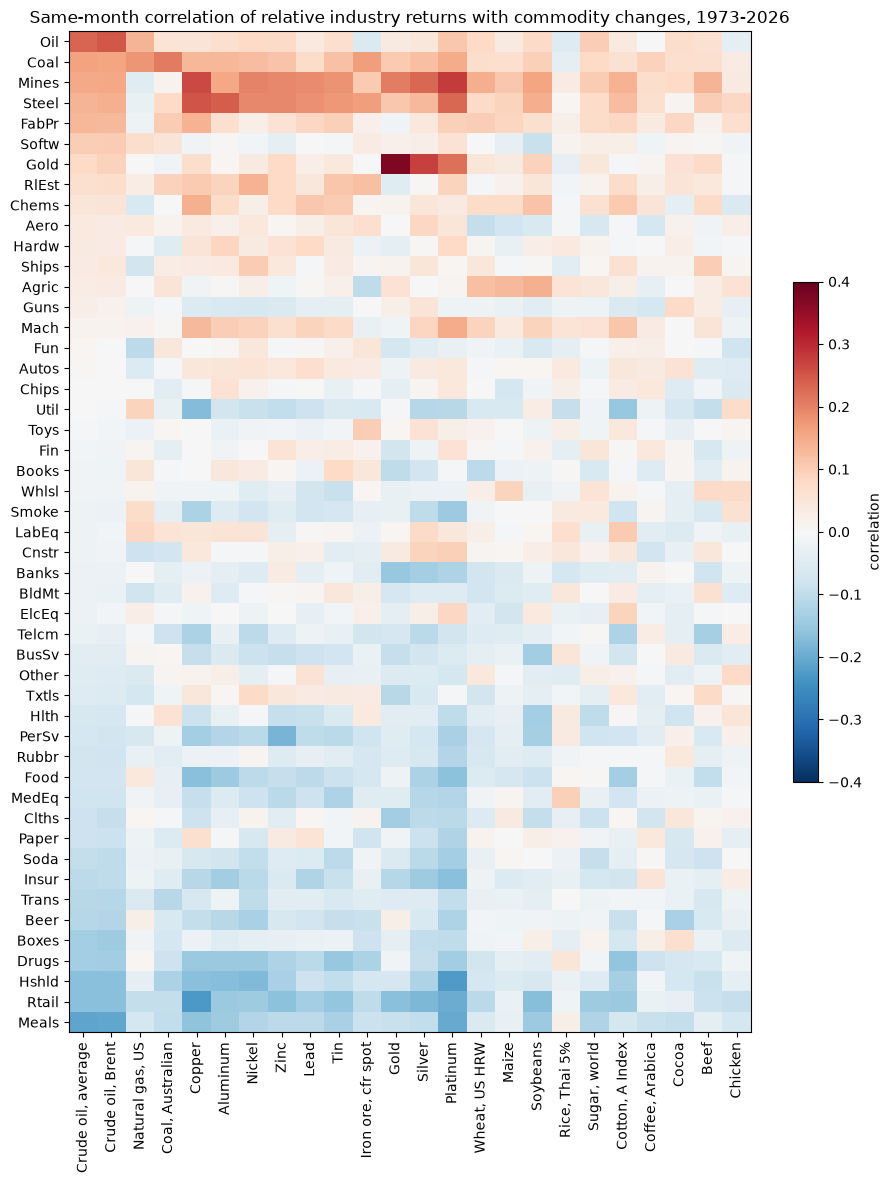

In [565]:
# Correlation of industry returns with commodity changes in the same month, since 1973.
# Industry returns are taken relative to the average industry.
relative_returns = industry_returns.sub(industry_returns.mean(axis=1), axis=0).loc[EVALUATION_START:]

# One column per commodity ("Gold" is both an industry and a commodity, so we avoid a concat)
correlations = pd.DataFrame({name: relative_returns.corrwith(since_1973[name]) for name in since_1973.columns})

# Industries sorted by their correlation with crude oil
correlations = correlations.sort_values("Crude oil, average", ascending=False)

fig, ax = plt.subplots(figsize=(11, 13))
image = ax.imshow(correlations, cmap="RdBu_r", vmin=-0.4, vmax=0.4, aspect="auto")
ax.set_xticks(range(len(correlations.columns)), correlations.columns, rotation=90)
ax.set_yticks(range(len(correlations.index)), correlations.index)
fig.colorbar(image, ax=ax, shrink=0.5, label="correlation")
ax.set_title("Same-month correlation of relative industry returns with commodity changes, 1973-2026")
plt.show()

In [566]:
# For each commodity group: the average correlation of each industry with the commodities of the group,
# then the industries at both ends with their correlation (a value beyond +/-0.08 is about two standard errors)
group_correlations = pd.DataFrame({group: correlations[names].mean(axis=1) for group, names in COMMODITY_GROUPS.items()})


def with_values(series):
    """Write 'Industry (+0.12), ...' from a series of correlations."""
    return ", ".join(f"{industry} ({value:+.2f})" for industry, value in series.items())


summary = {}
for group in group_correlations.columns:
    ranked = group_correlations[group].sort_values(ascending=False)
    summary[group] = {
        "commodities in the group": len(COMMODITY_GROUPS[group]),
        "industries with |correlation| > 0.08": int((ranked.abs() > 0.08).sum()),
        "most positive industries (correlation)": with_values(ranked.head(4)),
        "most negative industries (correlation)": with_values(ranked.tail(4).iloc[::-1]),  # most negative first
    }
summary = pd.DataFrame(summary).T
summary.index.name = "commodity group"

pd.set_option("display.max_colwidth", None)  # show the full lists
summary

,commodities in the group,industries with |correlation| > 0.08,most positive industries (correlation),most negative industries (correlation)
commodity group,,,,
energy,4,11,"Coal (+0.18), Oil (+0.17), FabPr (+0.09), Steel (+0.08)","Meals (-0.15), Rtail (-0.13), Hshld (-0.12), Trans (-0.10)"
industrial metals,7,14,"Steel (+0.20), Mines (+0.18), Coal (+0.12), RlEst (+0.10)","Rtail (-0.15), Drugs (-0.14), Hshld (-0.13), Meals (-0.12)"
precious metals,3,18,"Gold (+0.29), Mines (+0.24), Steel (+0.16), Coal (+0.12)","Rtail (-0.18), Insur (-0.14), Hshld (-0.14), Banks (-0.14)"
grains,4,3,"Mines (+0.11), Agric (+0.11), Steel (+0.08), Mach (+0.07)","Rtail (-0.08), Aero (-0.06), Banks (-0.06), Hshld (-0.05)"
softs,4,3,"Mines (+0.10), Coal (+0.07), FabPr (+0.07), Steel (+0.07)","Meals (-0.09), Rtail (-0.09), Drugs (-0.08), Hshld (-0.07)"
livestock,2,3,"Steel (+0.09), Mines (+0.09), Whlsl (+0.08), Ships (+0.06)","Rtail (-0.09), Hshld (-0.06), Food (-0.05), Meals (-0.05)"


## 3. Analytics and learning strategies

### 3.1 Backtesting framework

All strategies are evaluated with the same procedure. Let $r_{i,t}$ be the return of industry $i$ in month $t$, in percent, for $i = 1, \dots, N$ with $N = 49$.

**1. Forecast.** At the end of month $t$, the strategy produces a forecast $\hat{r}_{i,t+1}$ of next month's return of every industry, using only information available at $t$.

**2. Portfolio.** The forecasts are turned into a long-short portfolio. The position in industry $i$ is proportional to its forecast minus the average forecast $\hat{m}_{t+1} = \frac{1}{N} \sum_{j} \hat{r}_{j,t+1}$:

$$h_{i,t} = \frac{\hat{r}_{i,t+1} - \hat{m}_{t+1}}{\sum_{j=1}^{N} \left| \hat{r}_{j,t+1} - \hat{m}_{t+1} \right|}.$$

Industries with a forecast above the average are bought, the others are sold. The portfolio is cash-neutral, $\sum_i h_{i,t} = 0$, with a gross leverage of one, $\sum_i |h_{i,t}| = 1$.

**3. P&L.** The portfolio is held during month $t+1$:

$$\text{pnl}_{t+1} = \sum_{i=1}^{N} h_{i,t} \, r_{i,t+1}.$$

**4. Performance.** The annualised Sharpe ratio of the monthly P&L over January 1973 to September 2026:

$$\text{SR} = \sqrt{12} \, \frac{\text{mean}(\text{pnl})}{\text{std}(\text{pnl})}.$$

Mean-variance optimisation would replace step 2 by $h_t \propto V^{-1} \hat{r}_{t+1}$, with $V$ the covariance matrix of the industry returns. With $N = 49$ and monthly data, $V$ estimated over a few years is noisy, and singular on windows shorter than 49 months, so we keep the simpler rule above. The Sharpe ratio does not depend on the scaling of the positions; only the cross-section of the forecasts matters.

**Baseline: industry momentum.** The first strategy forecasts next month's return with the average return of the past twelve months (Moskowitz and Grinblatt, 1999):

$$\hat{r}_{i,t+1} = \frac{1}{12} \sum_{k=0}^{11} r_{i,t-k}.$$

It also serves as a check of the implementation. The P&L of the same positions applied to the month in which they are computed, $\sum_i h_{i,t} \, r_{i,t}$, uses future information and cannot be traded. It must be far better than the tradable P&L; otherwise the lag between forecasts and returns is wrong.

In [567]:
def sharpe_ratio(pnl):
    """Annualised Sharpe ratio of a monthly P&L series."""
    return np.sqrt(12) * pnl.mean() / pnl.std()


def long_short_positions(predictions):
    """Cash-neutral positions from one month of predictions: demeaned across industries, gross leverage of one."""
    centered = predictions - predictions.mean()
    return centered / centered.abs().sum()


def backtest(predictions, returns, start=EVALUATION_START):
    """Monthly P&L of the long-short portfolio built from the predictions at t and held during t+1."""
    positions = predictions.apply(long_short_positions, axis=1)  # one row of positions per month
    pnl = (positions.shift(1) * returns).sum(axis=1)  # positions decided at t earn the returns of t+1
    return pnl.loc[start:]


def plot_pnl(pnls, title):
    """Cumulative P&L (in %, not compounded) of one or several strategies, with their Sharpe ratios."""
    pnls = pd.DataFrame(pnls)
    ax = pnls.cumsum().plot(title=title)
    ax.legend([f"{name}: Sharpe ratio {sharpe_ratio(pnls[name]):.2f}" for name in pnls.columns])
    ax.set_xlabel("")
    ax.set_ylabel("cumulative P&L (%)")
    plt.show()

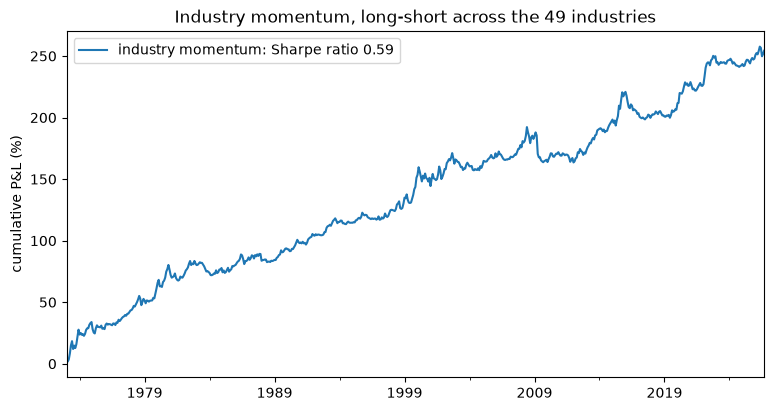

Sharpe ratio with look-ahead: 2.87 (tradable version: 0.59)


In [568]:
momentum_prediction = industry_returns.rolling(12).mean()  # average return over the past 12 months, known at t
pnl_momentum = backtest(momentum_prediction, industry_returns).rename("industry momentum")
plot_pnl(pnl_momentum, "Industry momentum, long-short across the 49 industries")

# Timing check: the same positions applied in the month they are computed (not tradable)
positions = momentum_prediction.apply(long_short_positions, axis=1)
look_ahead_pnl = (positions * industry_returns).sum(axis=1).loc[EVALUATION_START:]
print(f"Sharpe ratio with look-ahead: {sharpe_ratio(look_ahead_pnl):.2f} (tradable version: {sharpe_ratio(pnl_momentum):.2f})")

In [569]:
# Sharpe ratio of industry momentum by sub-period
sub_periods = {"1973-1999": pnl_momentum.loc["1973":"1999"],
               "2000-2007": pnl_momentum.loc["2000":"2007"],
               "2008-2026": pnl_momentum.loc["2008":]}
pd.Series({name: sharpe_ratio(pnl) for name, pnl in sub_periods.items()}, name="Sharpe ratio").round(2).to_frame().T

,1973-1999,2000-2007,2008-2026
Sharpe ratio,0.81,0.36,0.45


Industry momentum earns a Sharpe ratio of 0.59 over 1973-2026, 0.81 before 2000 and about 0.4 since, in line with the weaker momentum returns of the last two decades. This is the bar the commodity-based predictions have to clear.

### 3.2 Learning baseline: Ridge regression on past industry returns

In this second baseline, we replace the fixed momentum rule by a model fitted on the data. The target is next month's return of each industry relative to the average industry,

$$y_{i,t+1} = r_{i,t+1} - \frac{1}{N} \sum_{j=1}^{N} r_{j,t+1},$$

and the features at month $t$ are, for every industry, its average return over the past twelve months and its return over the last month, a vector $x_t$ of $2N = 98$ numbers. A single Ridge regression with $N$ outputs is fitted on standardised features (plus an intercept):

$$\min_{B} \; \sum_{s} \left\| y_{s+1} - B x_s \right\|^2 + \alpha \left\| B \right\|^2 .$$

Each industry's forecast can therefore depend on the past returns of all industries, not only on its own.

The model is refitted at the end of every month $t$ on a rolling window of the last 120 months, $s = t-120, \dots, t-1$, whose targets are all known at $t$, and the forecast is $\hat{y}_{t+1} = \hat{B} x_t$. Missing values, for industries that do not exist yet, are set to zero. We use $\alpha = 100$; the window length and $\alpha$ are varied in Section 4.

In [570]:
def walk_forward_predictions(model, features, target, window=120):
    """Refit the model at the end of every month on the last `window` months and forecast the next month.

    Row t of `features` is known at the end of month t and row t of `target` is the return of month t+1,
    so the model fitted at t uses rows t-window to t-1, whose targets are all known at t.
    """
    predictions = pd.DataFrame(np.nan, index=features.index, columns=target.columns)
    for t in range(window, len(features)):
        train = slice(t - window, t)
        model.fit(features.iloc[train], target.iloc[train])
        predictions.iloc[t] = model.predict(features.iloc[[t]])[0]
    return predictions

98 features, 49 targets


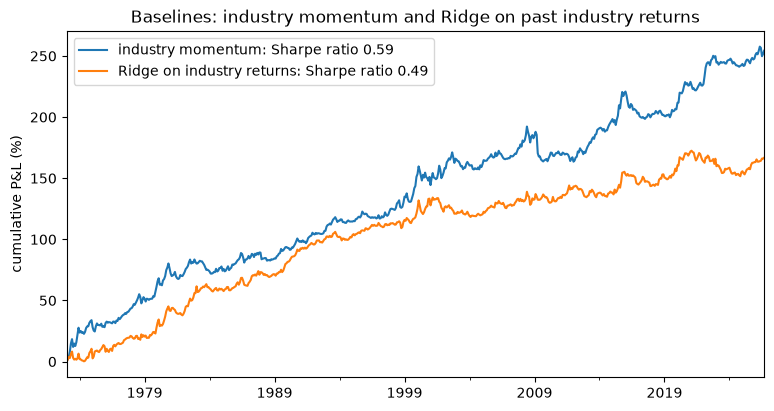

Correlation between the two P&Ls: 0.49


In [571]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Target: next month's return relative to the average industry
target = industry_returns.sub(industry_returns.mean(axis=1), axis=0).shift(-1)

# Features at month t: for every industry, its average return over the past 12 months and its last month's return
industry_features = pd.concat({"momentum_12m": industry_returns.rolling(12).mean(),
                               "last_month": industry_returns}, axis=1)
print(f"{industry_features.shape[1]} features, {target.shape[1]} targets")

ridge_industry = make_pipeline(StandardScaler(), Ridge(alpha=100))
forecasts_ridge_industry = walk_forward_predictions(ridge_industry, industry_features.fillna(0), target.fillna(0), window=120)
pnl_ridge_industry = backtest(forecasts_ridge_industry, industry_returns).rename("Ridge on industry returns")

plot_pnl({"industry momentum": pnl_momentum, "Ridge on industry returns": pnl_ridge_industry},
         "Baselines: industry momentum and Ridge on past industry returns")
print(f"Correlation between the two P&Ls: {pnl_momentum.corr(pnl_ridge_industry):.2f}")

The Ridge baseline reaches a Sharpe ratio of 0.49, below the simple momentum rule (0.59): with 98 noisy features, the extra flexibility does not pay on its own. The question for the next section is whether adding commodity changes to the same model improves on this.

### 3.3 Adding the commodity changes

**What is tested.** If last month's commodity moves carry information about next month's industry returns, a model that sees them should forecast better than the same model without them. The regression of Section 3.2 is therefore extended with the commodity changes, everything else (window, $\alpha$, standardisation, portfolio rule) being kept identical:

$$y_{t+1} = B \, x_t + C \, \Delta p_t + \varepsilon_{t+1}, \qquad \Delta p_{c,t} = 100 \left( \log P_{c,t} - \log P_{c,t-1} \right),$$

where $x_t$ holds the 98 past industry returns of Section 3.2 and $\Delta p_t$ the changes of the 22 commodities (iron ore and coal left out, see Section 2.5). $C$ is a $49 \times 22$ matrix of coefficients. The hypothesis says that $C$ is not zero, with positive entries for producers and negative ones for users.

**Three specifications** are run with the same walk-forward procedure:

1. past industry returns only ($C = 0$): the baseline of Section 3.2;
2. commodity changes only ($B = 0$): how much signal do they carry by themselves?
3. both.

**How to read the results.** Specifications 1 and 3 are nested: the only difference is the 22 extra columns, so any change in performance comes from the commodity information. Besides the Sharpe ratios, we report the mean monthly P&L difference $\bar{d}$ between 3 and 1; the two portfolios are built on the same months, so this is a paired test. Finally $\hat{C}$, estimated once over 1973-2026, is drawn as an industry × commodity map in the same industry order as the same-month correlations of Section 2.6, to see which pairs the model relies on.

22 commodity features, 120 features in total


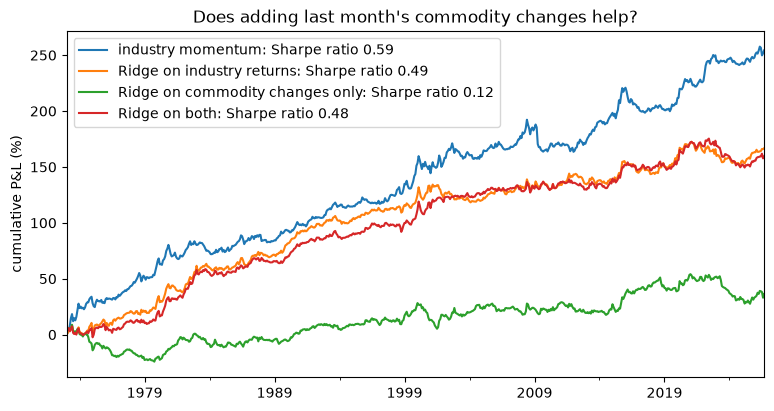

Monthly P&L difference, both minus industry only: mean -0.012% per month


In [572]:
# Commodity features at month t: last month's change of each commodity (iron ore and coal left out, see 2.5)
main_commodities = [name for name in commodity_changes.columns if name not in ["Iron ore, cfr spot", "Coal, Australian"]]
commodity_features = pd.concat({"commodity_1m": commodity_changes[main_commodities]}, axis=1)
both_features = pd.concat([industry_features, commodity_features], axis=1)
print(f"{commodity_features.shape[1]} commodity features, {both_features.shape[1]} features in total")

forecasts_commodities = walk_forward_predictions(make_pipeline(StandardScaler(), Ridge(alpha=100)),
                                                 commodity_features.fillna(0), target.fillna(0), window=120)
forecasts_both = walk_forward_predictions(make_pipeline(StandardScaler(), Ridge(alpha=100)),
                                          both_features.fillna(0), target.fillna(0), window=120)
pnl_commodities = backtest(forecasts_commodities, industry_returns).rename("Ridge on commodity changes only")
pnl_both = backtest(forecasts_both, industry_returns).rename("Ridge on industry returns + commodity changes")

plot_pnl({"industry momentum": pnl_momentum, "Ridge on industry returns": pnl_ridge_industry,
          "Ridge on commodity changes only": pnl_commodities, "Ridge on both": pnl_both},
         "Does adding last month's commodity changes help?")

difference = pnl_both - pnl_ridge_industry
print(f"Monthly P&L difference, both minus industry only: mean {difference.mean():+.3f}% per month")

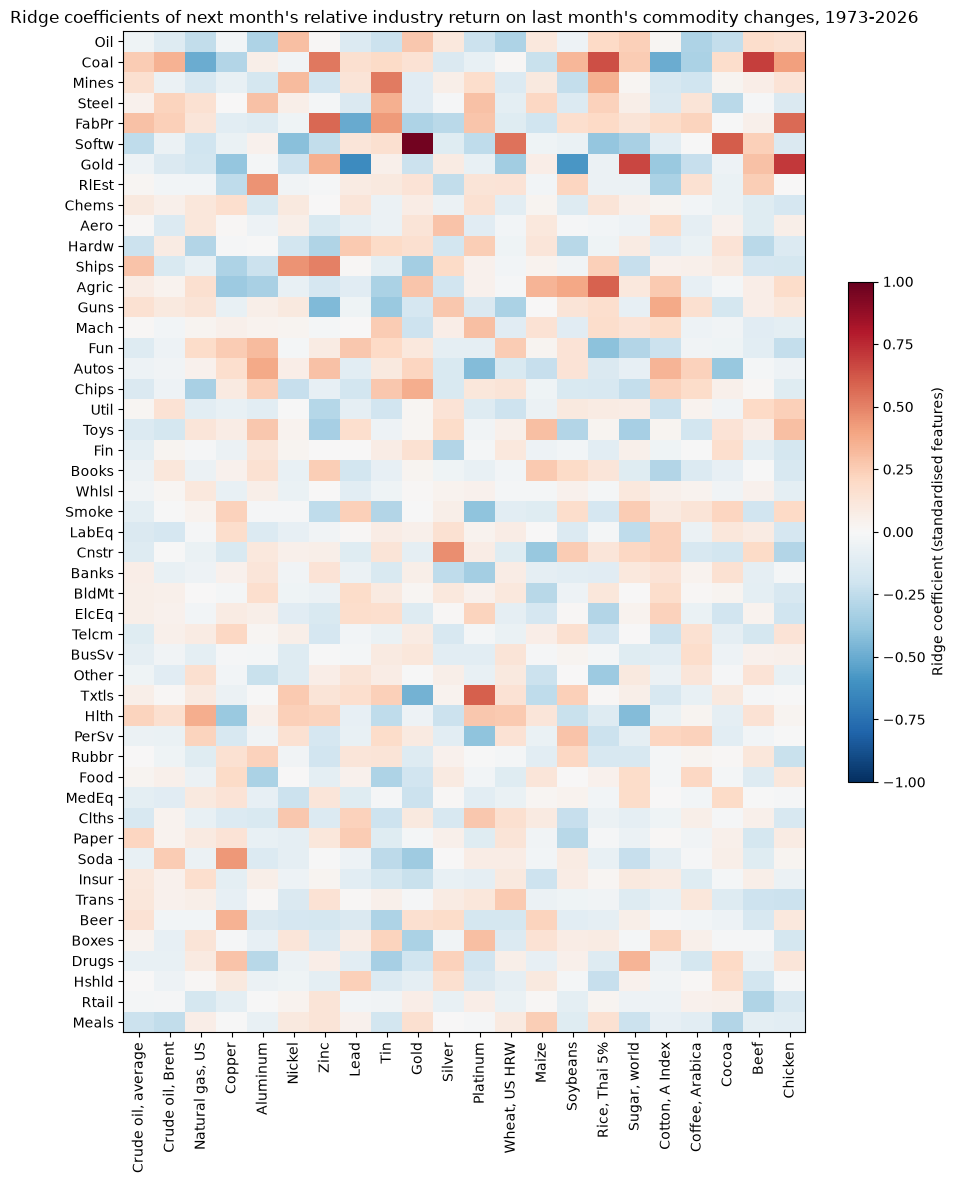

Largest coefficients: Softw x Gold (+0.97), Gold x Chicken (+0.71), Coal x Beef (+0.69), Gold x Sugar, world (+0.67), Coal x Rice, Thai 5% (+0.64), Gold x Lead (-0.63)
Oil x Crude oil, average: -0.04
Mines x Copper: -0.07
Gold x Gold: -0.22
Meals x Crude oil, average: -0.21


In [573]:
# What the model does with the commodities: coefficients on the 22 commodity features, one fit over 1973-2026
fit_months = target.loc[EVALUATION_START:].dropna(how="all").index  # months whose next-month return is known
ridge_full_sample = make_pipeline(StandardScaler(), Ridge(alpha=100))
ridge_full_sample.fit(both_features.loc[fit_months].fillna(0), target.loc[fit_months])
coefficients = pd.DataFrame(ridge_full_sample[-1].coef_, index=target.columns, columns=both_features.columns)
commodity_coefficients = coefficients["commodity_1m"].loc[correlations.index]  # same industry order as in Section 2.6

fig, ax = plt.subplots(figsize=(11, 13))
image = ax.imshow(commodity_coefficients, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(commodity_coefficients.columns)), commodity_coefficients.columns, rotation=90)
ax.set_yticks(range(len(commodity_coefficients.index)), commodity_coefficients.index)
fig.colorbar(image, ax=ax, shrink=0.5, label="Ridge coefficient (standardised features)")
ax.set_title("Ridge coefficients of next month's relative industry return on last month's commodity changes, 1973-2026")
plt.show()

# The largest coefficients, and the pairs the hypothesis is about
largest = commodity_coefficients.stack().abs().sort_values(ascending=False).head(6)
print("Largest coefficients:", ", ".join(f"{i} x {c} ({commodity_coefficients.loc[i, c]:+.2f})" for i, c in largest.index))
for industry, commodity in [("Oil", "Crude oil, average"), ("Mines", "Copper"), ("Gold", "Gold"), ("Meals", "Crude oil, average")]:
    print(f"{industry} x {commodity}: {commodity_coefficients.loc[industry, commodity]:+.2f}")

Adding last month's commodity changes does not improve the forecasts: the Sharpe ratio is 0.48 with the commodities against 0.49 without, and the commodity changes alone give 0.12. The coefficient map explains why. The largest coefficients fall on pairs with no economic link (Softw × Gold, Gold × Chicken, Coal × Beef), while the pairs behind the hypothesis are close to zero (Oil × crude oil −0.04, Mines × copper −0.07). With 49 industries and 22 commodities, the regression estimates 1,078 commodity coefficients from 120 months, and mostly fits noise.

In this general form the hypothesis is rejected: a flexible model does not find lagged commodity information in industry returns. The next step tests the sharper version of the story. If information diffuses slowly, next month's relative return of an industry should move in the direction of its known exposure, the same-month correlation of Section 2.6 estimated on past data only, times this month's commodity move. That is a one-parameter test instead of 1,078.

### 3.4 A one-parameter test: the exposure-weighted commodity signal

Section 2.6 showed a stable same-month pattern: when a commodity rises, its producers go up and consumer industries go down. If this information reaches stock prices slowly, part of the response should arrive the following month. Rather than estimating $49 \times 22$ free coefficients as in Section 3.3, the forecast is built from exposures that are measured beforehand.

**Notation.** $y_{i,t} = r_{i,t} - \frac{1}{N} \sum_j r_{j,t}$ is the relative return of industry $i$ (Section 3.2), $\Delta p_{c,t}$ the change of commodity $c$ (Section 3.3), and $W = 120$ months the estimation window.

**Step 1: standardised commodity move.**

$$z_{c,t} = \frac{\Delta p_{c,t}}{\sigma_{c,t-1}}, \qquad \sigma_{c,t-1} = \operatorname{std}\left( \Delta p_{c,s} \right)_{s = t-W, \dots, t-1}.$$

**Step 2: exposure of each industry to each commodity.** The same-month correlation, estimated on the window ending at $t-1$:

$$\rho_{i,c,t-1} = \operatorname{corr}\left( y_{i,s}, \, \Delta p_{c,s} \right)_{s = t-W, \dots, t-1}.$$

**Step 3: signal.** For each commodity $c$, the product $\rho_{i,c,t-1} \, z_{c,t}$ converts this month's move of commodity $c$ into an expected move of industry $i$: the commodity's move in standard deviations, $z_{c,t}$, times the industry's sensitivity to that commodity, $\rho_{i,c,t-1}$. It is positive when the commodity moved in the direction that usually goes with a rise of the industry, and negative otherwise. Adding up the 22 commodities gives one number per industry,

$$s_{i,t} = \sum_{c=1}^{22} \rho_{i,c,t-1} \, z_{c,t},$$

which measures how favourable this month's commodity moves were for industry $i$, given the exposures measured up to $t-1$. After a one-standard-deviation rise of crude oil, for instance, the oil term is about $+0.2$ for Oil and $-0.2$ for Meals. Under slow diffusion, next month's relative return should go in the direction of $s_{i,t}$.

**Step 4: forecast and portfolio.** $\hat{y}_{i,t+1} = s_{i,t}$, with the positions of Section 3.1, $h_{i,t} \propto s_{i,t} - \frac{1}{N} \sum_j s_{j,t}$.

**Reported.** The Sharpe ratio of the portfolio; its correlation with industry momentum; the same test with the sum of Step 3 restricted to one commodity group; and the Sharpe ratio by sub-period.

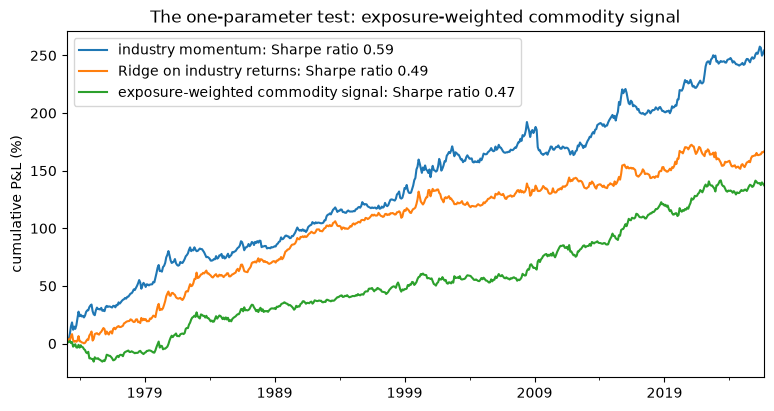

Sharpe ratio 0.47, correlation with industry momentum 0.14


In [574]:
def exposure_signal(commodities, window=120):
    """Signal s_{i,t}: sum over commodities of (same-month correlation estimated up to t-1) x (this month's standardised change)."""
    changes = commodity_changes[commodities]
    standardised_changes = changes / changes.rolling(window).std().shift(1)
    signal = pd.DataFrame(0.0, index=industry_returns.index, columns=industry_returns.columns)
    for name in commodities:
        exposure = relative_returns_all.rolling(window).corr(changes[name]).shift(1)  # months t-window to t-1
        signal = signal + exposure.mul(standardised_changes[name], axis=0).fillna(0)
    return signal


relative_returns_all = industry_returns.sub(industry_returns.mean(axis=1), axis=0)  # full sample, 2.6 used it from 1973
signal = exposure_signal(main_commodities)
pnl_signal = backtest(signal, industry_returns).rename("exposure-weighted commodity signal")

plot_pnl({"industry momentum": pnl_momentum, "Ridge on industry returns": pnl_ridge_industry,
          "exposure-weighted commodity signal": pnl_signal},
         "The one-parameter test: exposure-weighted commodity signal")
print(f"Sharpe ratio {sharpe_ratio(pnl_signal):.2f}, correlation with industry momentum {pnl_signal.corr(pnl_momentum):.2f}")

In [575]:
# Where does the signal come from? The same test by commodity group, then by sub-period
by_group = {}
for group, names in COMMODITY_GROUPS.items():
    names = [name for name in names if name in main_commodities]
    pnl = backtest(exposure_signal(names), industry_returns)
    by_group[group] = {"number of commodities in the signal": len(names), "Sharpe ratio of the signal, 1973-2026": sharpe_ratio(pnl)}
by_group["all 22 commodities"] = {"number of commodities in the signal": 22, "Sharpe ratio of the signal, 1973-2026": sharpe_ratio(pnl_signal)}
by_group = pd.DataFrame(by_group).T
by_group["number of commodities in the signal"] = by_group["number of commodities in the signal"].astype(int)
by_group.index.name = "commodity group used in the signal"
display(by_group.round(2))

sub_periods = {"1973-2026": pnl_signal,
               "1973-1999": pnl_signal.loc["1973":"1999"],
               "2000-2007": pnl_signal.loc["2000":"2007"],
               "2008-2026": pnl_signal.loc["2008":]}
sharpe_by_period = pd.Series({name: sharpe_ratio(pnl) for name, pnl in sub_periods.items()}, name="Sharpe ratio of the 22-commodity signal")
sharpe_by_period.index.name = "period"
sharpe_by_period.round(2).to_frame().T

,number of commodities in the signal,"Sharpe ratio of the signal, 1973-2026"
commodity group used in the signal,,
energy,3,0.20
industrial metals,6,0.29
precious metals,3,0.12
grains,4,0.15
softs,4,0.28
livestock,2,-0.07
all 22 commodities,22,0.47


period,1973-2026,1973-1999,2000-2007,2008-2026
Sharpe ratio of the 22-commodity signal,0.47,0.4,0.07,0.7


The structured signal works where the flexible regression did not: a Sharpe ratio of 0.47 over 1973-2026, against 0.12 for the Ridge on the same 22 commodity changes. Its correlation with industry momentum is only 0.14, so it is a new source of return rather than momentum in disguise. No single commodity group carries it: industrial metals (0.29) and softs (0.28) are the strongest, energy reaches only 0.20 and livestock nothing; each group is too weak on its own, and the result comes from adding up many weak signals. The effect does not fade over time: the Sharpe ratio is 0.40 before 2000, close to zero in 2000-2007 and 0.70 since 2008, so it shows none of the post-publication decay documented by McLean and Pontiff (2016) for published predictors.

*Next step:* Section 4, robustness: exposure window, end-of-month prices, the producer/user split, and the combination with momentum.